## Date presentation

In [ ]:
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install plotly

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

In [3]:
df = pd.read_csv("data.csv")

In [4]:
tdf = df[~(((df["From"] > "2003-02-21") & (df["From"] < "2003-06-23")) | ((df["From"] > "2020-01-23") & (df["From"] < "2023-03-01")) | (df["From"] < "2004-01-01"))]


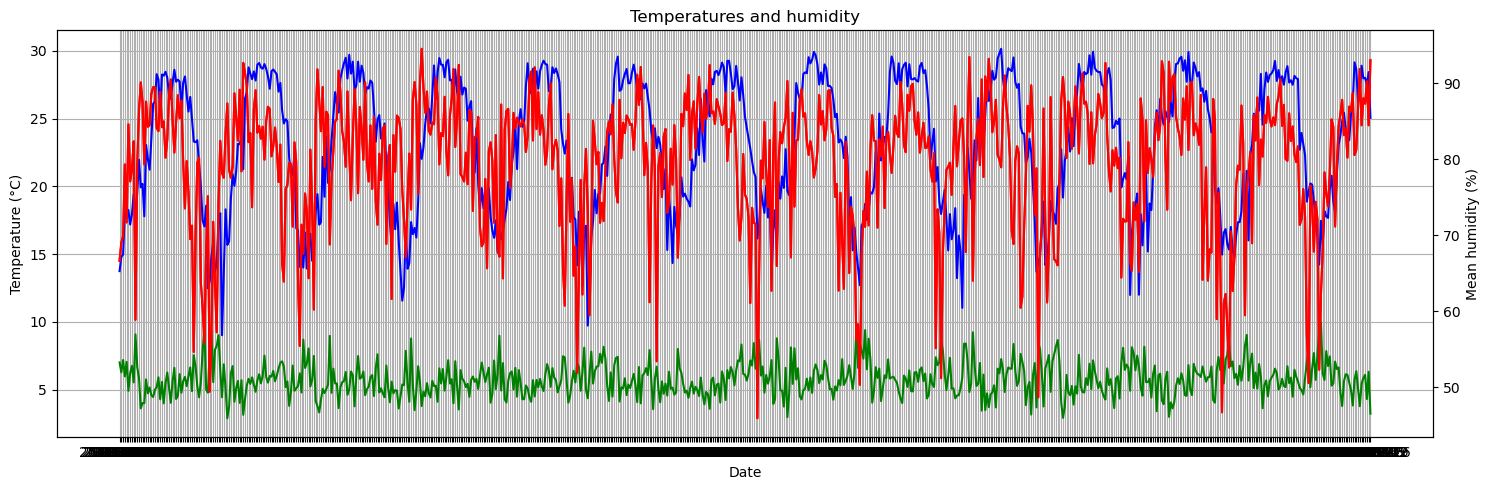

In [5]:
# to-do
fig, ax1 = plt.subplots(figsize=(15, 5))

ax1.plot(df["From"], df["Mean temperature (°C)"], color="blue")
ax1.plot(df["From"], df["Diurnal temperature range (°C)"], color="green")
ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)")

ax2 = ax1.twinx()
line2 = ax2.plot(df["From"], df["Mean humidity (%)"], color="red")
ax2.plot(df["From"], df["Mean humidity (%)"], color="red")
ax2.set_ylabel("Mean humidity (%)")

ax1.grid()
'''
legend_elements = [
    Line2D(), 
    Line2D()
]
ax1.legend(handle=legend_elements)
'''

plt.title("Temperatures and humidity")
plt.tight_layout()
plt.show()

,H1,H3,B,AandB
Diurnal temperature range (°C),-0.043189,-0.045188,0.004429,-0.052733
Mean temperature (°C),-0.218821,0.040794,-0.253483,-0.210367
Mean humidity (%),0.026049,0.053294,-0.009666,0.046032
Solar radiation (MJ/m²),-0.179775,0.045184,-0.152551,-0.140473


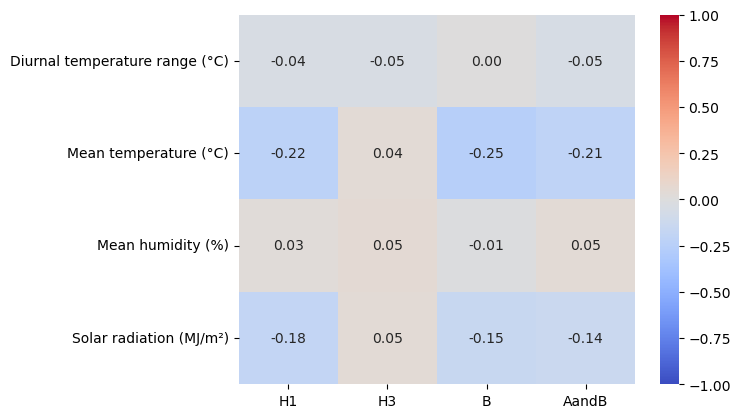

In [6]:
# correlation between meteorlogical factors and influenza detections
with pd.option_context("display.max_rows", 8):
    corr_tdf = tdf[["Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)", "H1", "H3", "B", "AandB"]].corr()
    corr_tdf = corr_tdf.loc[["Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)"], ["H1", "H3", "B", "AandB"]]
    display(corr_tdf)
sns.heatmap(corr_tdf, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.show()

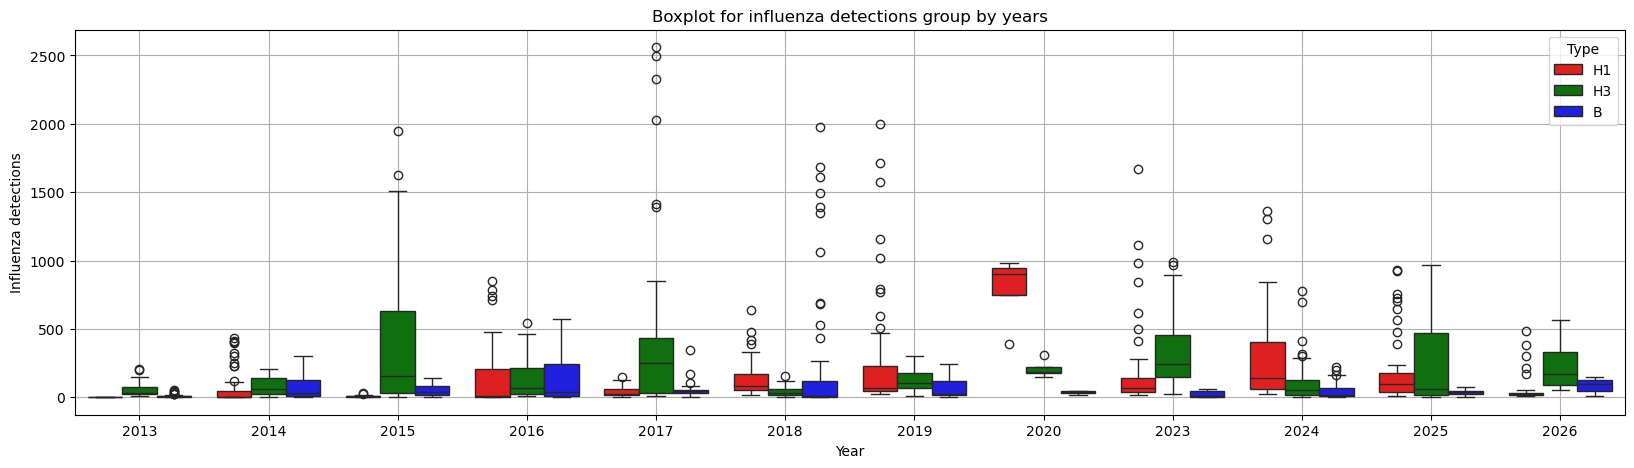

In [7]:
df_long = tdf.melt(
    id_vars=["Year"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

plt.figure(figsize=(20, 5))
sns.boxplot(df_long, x="Year", y="Influenza detections", hue="Type", palette=["red", "green", "blue"])

plt.title("Boxplot for influenza detections group by years")
plt.xlabel("Year")
plt.ylabel("Influenza detections")
plt.grid()
plt.show()

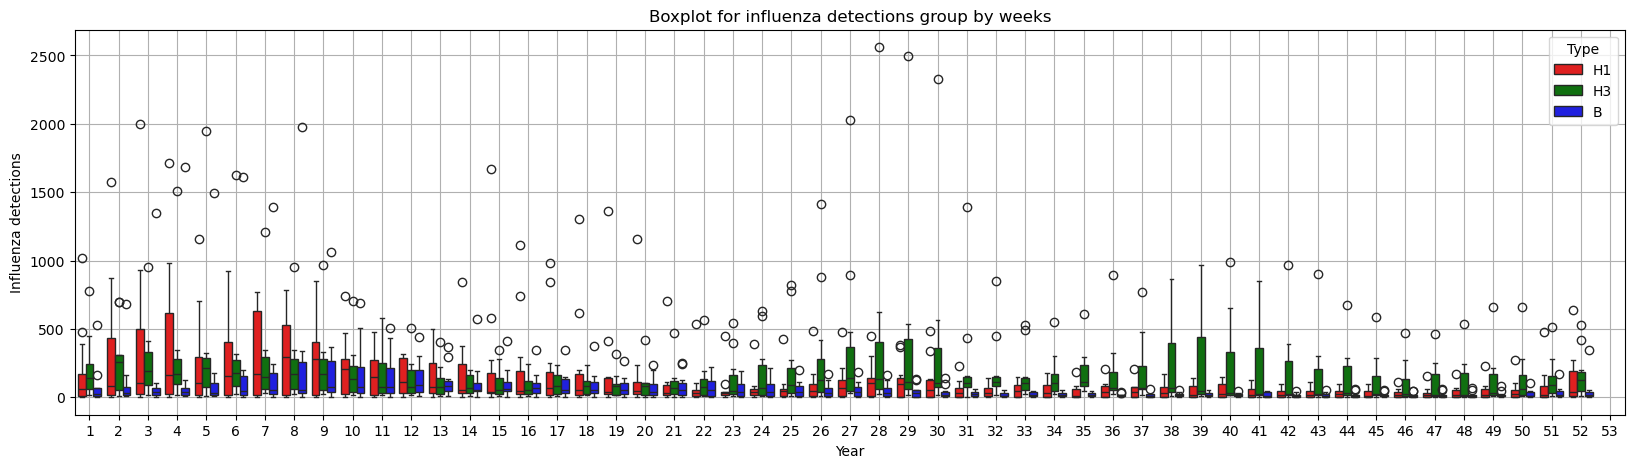

In [8]:
df_long = tdf.melt(
    id_vars=["Week"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

plt.figure(figsize=(20, 5))
sns.boxplot(df_long, x="Week", y="Influenza detections", hue="Type", palette=["red", "green", "blue"])

plt.title("Boxplot for influenza detections group by weeks")
plt.xlabel("Year")
plt.ylabel("Influenza detections")
plt.grid()
plt.show()

In [9]:
# to-do
df_long = tdf.melt(
    id_vars=["Week"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

fig = px.line(df_long, "Week", "Influenza detections", color="Type",
              title="Number of detections based on timeline", 
              width=1500, height=600
             )
for year in sorted(tdf["Year"].unique()):
    start = pd.Timestamp(int(year), 6, 1)
    end = pd.Timestamp(int(year), 8, 31)
    fig.add_vrect(start, end, line_width=0, fillcolor="red", opacity=0.3)
    
    start = pd.Timestamp(int(year), 1, 1)
    end = pd.Timestamp(int(year), 2, 28)
    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

    start = pd.Timestamp(int(year), 12, 1)
    end = pd.Timestamp(int(year), 12, 31)

    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(255, 0, 0, 0.3)"),
        name="Winter", 
        showlegend=True,
    )
)
fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(0, 0, 255, 0.3)"),
        name="Summer", 
        showlegend=True,
    )
)

fig.show()

In [10]:
df_long = tdf.melt(
    id_vars=["From"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

fig = px.line(df_long, "From", "Influenza detections", color="Type",
              title="Number of detections based on timeline", 
              width=1500, height=600
             )
for year in sorted(tdf["Year"].unique()):
    start = pd.Timestamp(int(year), 6, 1)
    end = pd.Timestamp(int(year), 8, 31)
    fig.add_vrect(start, end, line_width=0, fillcolor="red", opacity=0.3)
    
    start = pd.Timestamp(int(year), 1, 1)
    end = pd.Timestamp(int(year), 2, 28)
    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

    start = pd.Timestamp(int(year), 12, 1)
    end = pd.Timestamp(int(year), 12, 31)

    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(255, 0, 0, 0.3)"),
        name="Winter", 
        showlegend=True,
    )
)
fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(0, 0, 255, 0.3)"),
        name="Summer", 
        showlegend=True,
    )
)

fig.show()

In [ ]:
# graph of influenza based on timeline
fig, ax = plt.subplots(figsize=(85, 15))

ax.plot(tdf["From"], tdf["H1"], color="red")
ax.plot(tdf["From"], tdf["H3"], color="green")
ax.plot(tdf["From"], tdf["B"], color="blue")
ax.grid()

ax.set_title("Number of detections")
ax.set_xlabel("Year")
ax.set_ylabel("Number of detections")
ax.legend(["AH1", "AH3", "B"])


for year in sorted(tdf["Year"].unique()): 
    start = pd.Timestamp(int(year), 6, 1)
    end = pd.Timestamp(int(year), 8, 31)
    ax.axvspan(start, end, color="#ffd1dc")

    mid_pt = start + (end - start) / 2
    ax.text(mid_pt, 2000, "Summer", horizontalalignment="center", verticalalignment="center", rotation=90, va="bottom", color="dimgray")

    start = pd.Timestamp(int(year), 1, 1)
    end = pd.Timestamp(int(year), 2, 28)
    ax.axvspan(start, end, color="#ADD8E6")

    mid_pt = start + (end - start) / 2
    ax.text(mid_pt, 2000, "Winter", horizontalalignment="center", verticalalignment="center", rotation=90, va="bottom", color="dimgray")

    start = pd.Timestamp(int(year), 12, 1)
    end = pd.Timestamp(int(year), 12, 31)
    ax.axvspan(start, end, color="#ADD8E6")

plt.show()

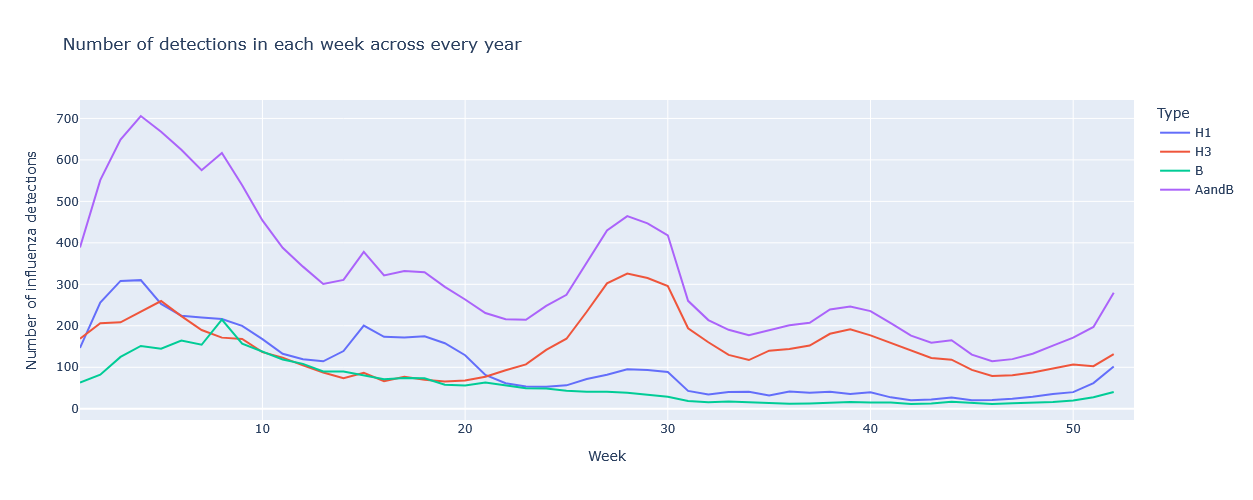

In [12]:
tdf = df.drop(["Year", "From"], axis=1).groupby("Week").mean()
tdf["Week"] = tdf.index
df_long = tdf.melt(
    id_vars=["Week"],
    value_vars=["H1", "H3", "B", "AandB"],
    var_name="Type",  
    value_name="Number of influenza detections", 
)

fig = px.line(df_long, "Week", "Number of influenza detections", color="Type", 
              title="Number of detections in each week across every year", 
              width=1000, height=500
             )
fig.show()